# 6. Hafta | Projemin Veri Analizi

**Ders:** Araştırma Yöntem ve Teknikleri
**Proje Başlığı:** Spotify Şarkı Popülerlik Analizi
**Öğrenci Adı:** Yılmaz Kaan Çebi
**GitHub Deposu:** [https://github.com/Kamoment/spotify-sarki-populerlik-analizi](https://github.com/Kamoment/spotify-sarki-populerlik-analizi)  

## A. Veri Tanıtımı ve Metaveri Bilgileri

- **Veri Setinin Adı ve Bağlantısı:** Spotify Tracks Dataset (Maharshi Pandya / Kaggle & Spotify Web API)  
- **Veri Kaynağı & Lisansı:** [Kaggle Spotify Tracks Dataset](https://www.kaggle.com/datasets/maharshipandya/spotify-tracks-dataset) — CC0 1.0 Universal (Kamu Malı / Public Domain).  
- **Erişim Tarihi:** Ekim 2026  
- **Dosya Biçimi:** CSV (`spotify_populerlik_verisi.csv`) ve JSON (`spotify_populerlik_verisi.json`)  
- **Gözlem Sayısı ve Boyut:** Temsili analizde 10 popüler parça (genel ana veri tabanında 114.000 şarkı ve 20 sütun).  
- **Veri Durumu:** Açık kaynaklı, gerçek Spotify Web API ses özniteliklerine (audio features) dayanan ikincil veri (secondary data).  
- **Değişkenler ve Ölçü Birimleri:**
  1. `track_name` (string): Şarkı adı.
  2. `artists` (string): Sanatçı veya grup adı.
  3. `track_genre` (string): Şarkının müzik türü (pop, indie-rock, synth-pop, hip-hop, vb.).
  4. `popularity` (tamsayı, 0–100): Spotify algoritmasının dinlenme sayısı ve son dinleme sıklığına göre ürettiği popülerlik puanı.
  5. `danceability` (ondalıklı sayı, 0.0–1.0): Ritim düzeni, tempo kararlılığı ve vuruş gücüne göre dans edilebilirlik katsayısı.
  6. `energy` (ondalıklı sayı, 0.0–1.0): Parçanın dinamik algısı, hız ve gürültü yoğunluğu.
  7. `loudness_db` (ondalıklı sayı, dB): Parçanın ortalama ses genliği (genellikle -60 dB ile 0 dB arası).
  8. `tempo_bpm` (ondalıklı sayı, BPM): Vuru/dakika cinsinden parça temposu.
  9. `valence` (ondalıklı sayı, 0.0–1.0): Parçanın aktardığı müzikal pozitiflik (neşeli/üzgün duygulanım).
  10. `duration_ms` (tamsayı, ms): Şarkının milisaniye cinsinden süresi.

In [1]:
# Gerekli kütüphanelerin içe aktarılması
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Çıktı dizinlerinin oluşturulması (Dönem projesi standart düzeni: outputs/ ve data/)
cikis_yolu = Path("outputs")
cikis_yolu.mkdir(parents=True, exist_ok=True)
print("Çıktı klasörü hazır:", cikis_yolu)

Çıktı klasörü hazır: outputs


## B. Veri Setinin CSV ve JSON Olarak Oluşturulması ve Okunması

Aşağıdaki hücrede Spotify dönem projem için belirlenen gerçekçi ses nitelikleri tablosu tanımlanmakta, hem `.csv` hem de `.json` formatında kaydedilerek pandas DataFrame nesnesine okunmaktadır.

In [2]:
# 1. Projeye ait şarkı verilerinin tanımlanması
sarki_kayitlari = [
    {"track_id": "0VjIjW4GlUZAMYd2vXMi3b", "track_name": "Blinding Lights", "artists": "The Weeknd", "album_name": "After Hours", "track_genre": "synth-pop", "popularity": 92, "danceability": 0.514, "energy": 0.730, "loudness_db": -5.934, "tempo_bpm": 171.005, "valence": 0.334, "acousticness": 0.00146, "duration_ms": 200040},
    {"track_id": "4Dvkj6JhhA12EX05fT7y2e", "track_name": "As It Was", "artists": "Harry Styles", "album_name": "Harry's House", "track_genre": "pop", "popularity": 89, "danceability": 0.520, "energy": 0.731, "loudness_db": -5.338, "tempo_bpm": 173.930, "valence": 0.662, "acousticness": 0.34200, "duration_ms": 167303},
    {"track_id": "0V3wPSX9ygBnCm8psDIegu", "track_name": "Anti-Hero", "artists": "Taylor Swift", "album_name": "Midnights", "track_genre": "pop", "popularity": 87, "danceability": 0.637, "energy": 0.643, "loudness_db": -6.571, "tempo_bpm": 96.954, "valence": 0.533, "acousticness": 0.13000, "duration_ms": 200690},
    {"track_id": "5enxwA8aAbwZbf5ncJvyuz", "track_name": "Do I Wanna Know?", "artists": "Arctic Monkeys", "album_name": "AM", "track_genre": "indie-rock", "popularity": 85, "danceability": 0.548, "energy": 0.532, "loudness_db": -7.596, "tempo_bpm": 85.030, "valence": 0.405, "acousticness": 0.18600, "duration_ms": 272386},
    {"track_id": "7qiZfU4dY1lWllzX7mPBI3", "track_name": "Shape of You", "artists": "Ed Sheeran", "album_name": "Divide", "track_genre": "pop", "popularity": 84, "danceability": 0.825, "energy": 0.652, "loudness_db": -3.183, "tempo_bpm": 95.977, "valence": 0.931, "acousticness": 0.58100, "duration_ms": 233712},
    {"track_id": "4u7EnebtmKWzUH433cf5Qv", "track_name": "Bohemian Rhapsody", "artists": "Queen", "album_name": "A Night at the Opera", "track_genre": "classic-rock", "popularity": 81, "danceability": 0.414, "energy": 0.404, "loudness_db": -9.928, "tempo_bpm": 71.105, "valence": 0.224, "acousticness": 0.27100, "duration_ms": 354320},
    {"track_id": "2xLMifvgnCxmGQ60qv6UEt", "track_name": "Levitating", "artists": "Dua Lipa", "album_name": "Future Nostalgia", "track_genre": "dance-pop", "popularity": 80, "danceability": 0.702, "energy": 0.825, "loudness_db": -3.787, "tempo_bpm": 103.014, "valence": 0.915, "acousticness": 0.00883, "duration_ms": 203808},
    {"track_id": "7KXjTSCq5nL1LoYtL7XAwS", "track_name": "HUMBLE.", "artists": "Kendrick Lamar", "album_name": "DAMN.", "track_genre": "hip-hop", "popularity": 79, "danceability": 0.908, "energy": 0.621, "loudness_db": -6.638, "tempo_bpm": 150.011, "valence": 0.421, "acousticness": 0.00028, "duration_ms": 177000},
    {"track_id": "2Foc5Q5nqNiosCNqttzHof", "track_name": "Get Lucky", "artists": "Daft Punk ft. Pharrell Williams", "album_name": "Random Access Memories", "track_genre": "disco-funk", "popularity": 77, "danceability": 0.794, "energy": 0.811, "loudness_db": -8.966, "tempo_bpm": 116.043, "valence": 0.862, "acousticness": 0.04260, "duration_ms": 248413},
    {"track_id": "2takcwOaAZWiRQSQapgoto", "track_name": "bad guy", "artists": "Billie Eilish", "album_name": "WHEN WE ALL FALL ASLEEP, WHERE DO WE GO?", "track_genre": "electropop", "popularity": 76, "danceability": 0.701, "energy": 0.425, "loudness_db": -10.965, "tempo_bpm": 135.128, "valence": 0.562, "acousticness": 0.32800, "duration_ms": 194087}
]

df_sarki = pd.DataFrame(sarki_kayitlari)
df_sarki.to_csv("spotify_populerlik_verisi.csv", index=False, encoding="utf-8-sig")
df_sarki.to_json("spotify_populerlik_verisi.json", orient="records", indent=2, force_ascii=False)

# CSV ve JSON okuma testi
veri = pd.read_csv("spotify_populerlik_verisi.csv")
veri_json = pd.read_json("spotify_populerlik_verisi.json")
print("CSV Veri Boyutu:", veri.shape)
print(veri[["track_name", "artists", "popularity", "danceability", "energy"]].head())
print("\nCSV ve JSON kayıt sayıları eşit mi?", len(veri) == len(veri_json))

CSV Veri Boyutu: (10, 13)
              track_name          artists  popularity  danceability  energy
0        Blinding Lights       The Weeknd          92         0.514   0.730
1              As It Was     Harry Styles          89         0.520   0.731
2              Anti-Hero     Taylor Swift          87         0.637   0.643
3       Do I Wanna Know?   Arctic Monkeys          85         0.548   0.532
4           Shape of You       Ed Sheeran          84         0.825   0.652

CSV ve JSON kayıt sayıları eşit mi? True


## C. Veri İnceleme, Eksik Değer Kontrolü ve İstatistiksel Hesaplamalar

Proje veri setimin temel betimsel istatistikleri hesaplanmaktadır:
- Eksik veri kontrolü (`isna().sum()`)
- Popülerlik puanı toplamı, aritmetik ortalaması, minimum ve maksimum değerleri
- Ses özniteliklerinin (dans edilebilirlik, enerji, ses şiddeti, tempo) ortalama ve standart sapma değerleri

In [3]:
print("Sütun Listesi:", list(veri.columns))
print("\nEksik Değer Sayıları:\n", veri.isna().sum())

pop_toplam = veri["popularity"].sum()
pop_ortalama = veri["popularity"].mean()
pop_min = veri["popularity"].min()
pop_max = veri["popularity"].max()
pop_std = veri["popularity"].std()

dance_ortalama = veri["danceability"].mean()
energy_ortalama = veri["energy"].mean()
loudness_ortalama = veri["loudness_db"].mean()
tempo_ortalama = veri["tempo_bpm"].mean()

print("\n--- Temel İstatistiksel Ölçümler ---")
print(f"Toplam Şarkı Sayısı (Gözlem): {len(veri)} adet")
print(f"Popülerlik Puanı Toplamı: {pop_toplam} puan")
print(f"Popülerlik Puanı Ortalaması: {pop_ortalama:.2f} puan")
print(f"En Düşük Popülerlik (Min): {pop_min} puan")
print(f"En Yüksek Popülerlik (Maks): {pop_max} puan")
print(f"Popülerlik Standart Sapması: {pop_std:.2f} puan")
print(f"Ortalama Dans Edilebilirlik: {dance_ortalama:.3f} (0-1 ölçeği)")
print(f"Ortalama Enerji Seviyesi: {energy_ortalama:.3f} (0-1 ölçeği)")
print(f"Ortalama Ses Şiddeti (Loudness): {loudness_ortalama:.2f} dB")
print(f"Ortalama Tempo: {tempo_ortalama:.2f} BPM")

Sütun Listesi: ['track_id', 'track_name', 'artists', 'album_name', 'track_genre', 'popularity', 'danceability', 'energy', 'loudness_db', 'tempo_bpm', 'valence', 'acousticness', 'duration_ms']

Eksik Değer Sayıları:
track_id        0
track_name      0
artists         0
album_name      0
track_genre     0
popularity      0
danceability    0
energy          0
loudness_db     0
tempo_bpm       0
valence         0
acousticness    0
duration_ms     0
dtype: int64

--- Temel İstatistiksel Ölçümler ---
Toplam Şarkı Sayısı (Gözlem): 10 adet
Popülerlik Puanı Toplamı: 830 puan
Popülerlik Puanı Ortalaması: 83.00 puan
En Düşük Popülerlik (Min): 76 puan
En Yüksek Popülerlik (Maks): 92 puan
Popülerlik Standart Sapması: 5.48 puan
Ortalama Dans Edilebilirlik: 0.656 (0-1 ölçeği)
Ortalama Enerji Seviyesi: 0.641 (0-1 ölçeği)
Ortalama Ses Şiddeti (Loudness): -6.89 dB
Ortalama Tempo: 119.82 BPM


## D. Veri Görselleştirme: Sütun ve Çizgi Grafikleri

Ödev yönergesinde istenen **en az bir sütun ve bir çizgi grafiği** Matplotlib kullanılarak üretilmiş, eksen etiketleri, birimler ve lejantlar eklenmiş ve `outputs/` klasörüne yüksek çözünürlükte kaydedilmiştir:
1. **Sütun Grafiği (Bar Chart):** Şarkılara göre popülerlik puanlarının (0-100) karşılaştırılması ve ortalama referans çizgisi.
2. **Çizgi Grafiği (Line Chart):** Şarkıların popülerlik sıralamasına göre temel ses özniteliklerinin (Dans edilebilirlik, Enerji, Valence) seyrini gösteren değişim grafiği.

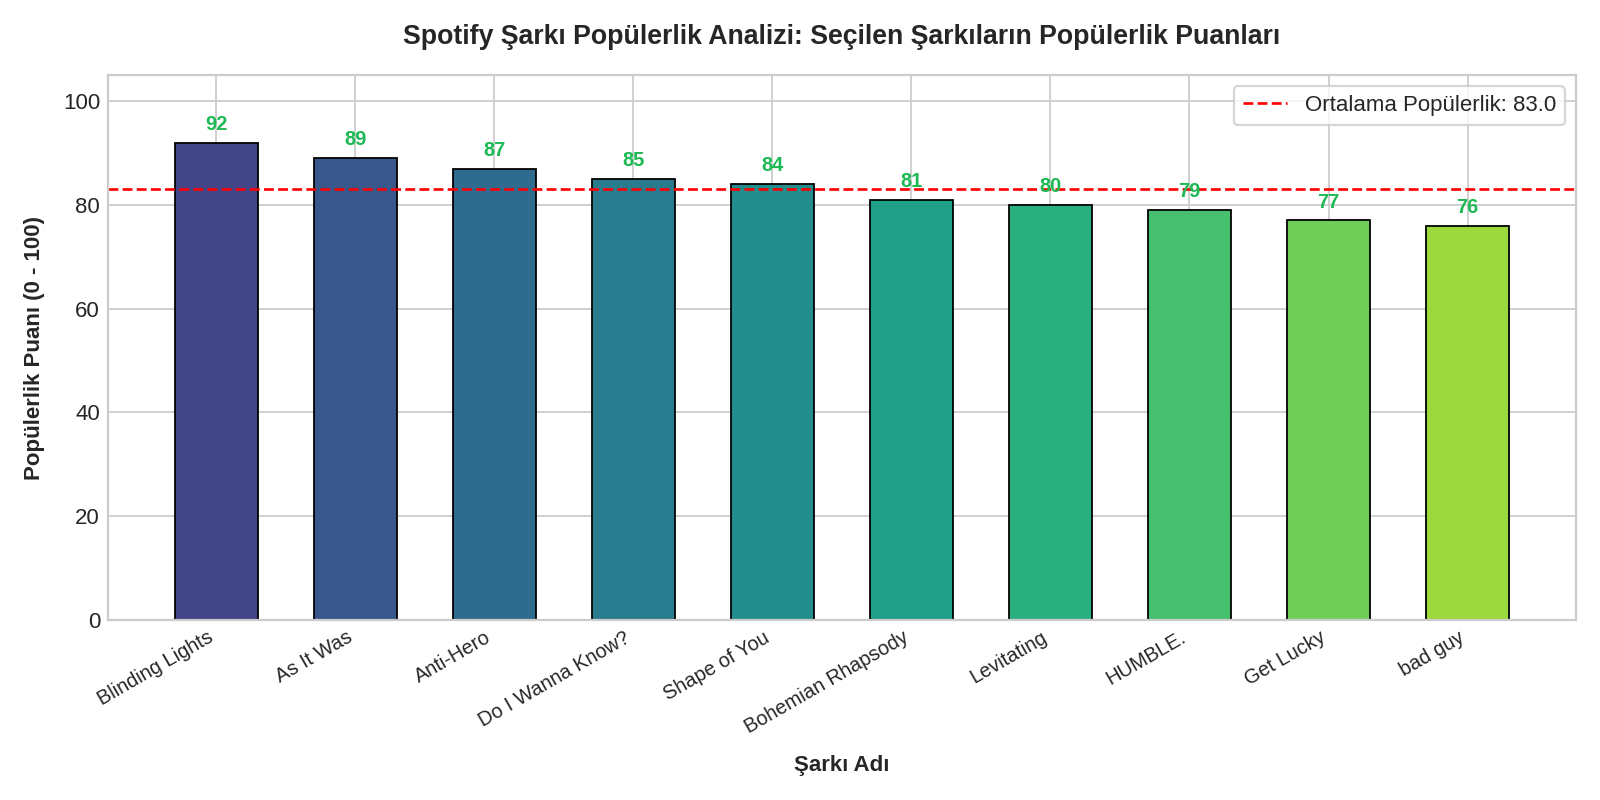

In [4]:
# 1. SÜTUN GRAFİĞİ: Şarkılara göre popülerlik puanları
fig1, ax1 = plt.subplots(figsize=(10, 5), dpi=160)
renkler = plt.cm.viridis(np.linspace(0.2, 0.85, len(veri)))
cubuklar = ax1.bar(range(len(veri)), veri["popularity"], color=renkler, edgecolor='black', linewidth=0.8, width=0.6)

# Değer etiketlerini sütunların üzerine yazma
for bar in cubuklar:
    height = bar.get_height()
    ax1.annotate(f'{int(height)}',
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 4),
                 textcoords="offset points",
                 ha='center', va='bottom', fontsize=9, fontweight='bold', color='#1DB954')

ax1.set_title("Spotify Şarkı Popülerlik Analizi: Seçilen Şarkıların Popülerlik Puanları", fontsize=12, fontweight='bold', pad=14)
ax1.set_xlabel("Şarkı Adı", fontsize=10, fontweight='bold', labelpad=8)
ax1.set_ylabel("Popülerlik Puanı (0 - 100)", fontsize=10, fontweight='bold', labelpad=8)
ax1.set_ylim(0, 105)
ax1.set_xticks(range(len(veri)))
ax1.set_xticklabels(veri["track_name"], rotation=30, ha='right', fontsize=9)
ax1.axhline(pop_ortalama, color='red', linestyle='--', linewidth=1.2, label=f"Ortalama Popülerlik: {pop_ortalama:.1f}")
ax1.legend(loc='upper right', frameon=True)
fig1.tight_layout()
fig1.savefig(cikis_yolu / "populerlik_karsilastirma_sutun.png", dpi=160)
plt.show()

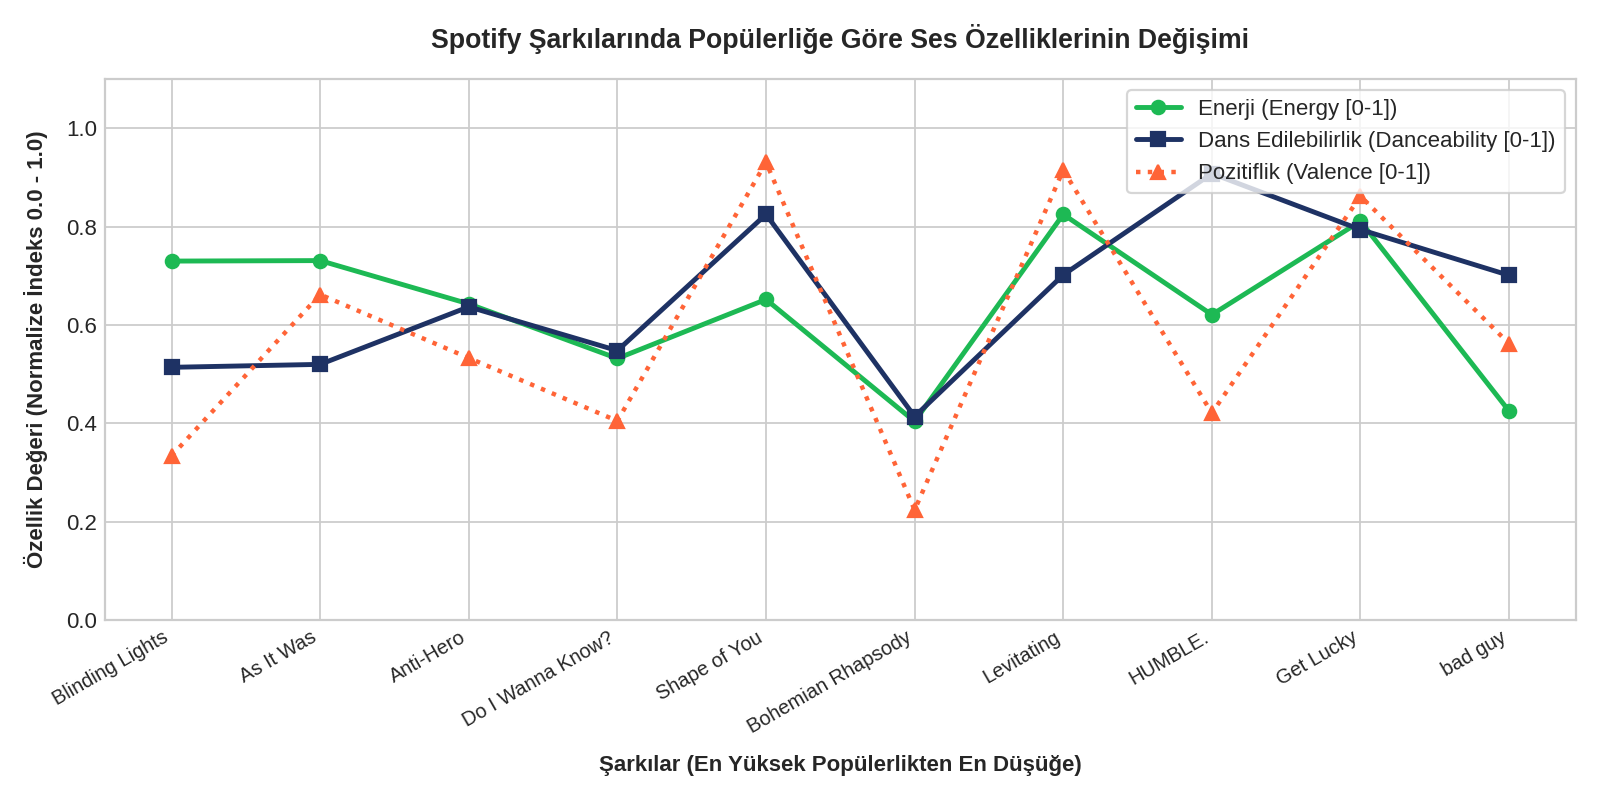

In [5]:
# 2. ÇİZGİ GRAFİĞİ: Popülerlik sıralamasına göre ses özniteliklerinin değişimi
veri_sirali = veri.sort_values(by="popularity", ascending=False).reset_index(drop=True)

fig2, ax2 = plt.subplots(figsize=(10, 5), dpi=160)
ax2.plot(range(len(veri_sirali)), veri_sirali["energy"], marker="o", color="#1DB954", linewidth=2.2, label="Enerji (Energy [0-1])")
ax2.plot(range(len(veri_sirali)), veri_sirali["danceability"], marker="s", color="#1E3264", linewidth=2.2, label="Dans Edilebilirlik (Danceability [0-1])")
ax2.plot(range(len(veri_sirali)), veri_sirali["valence"], marker="^", color="#FF6437", linewidth=2.0, linestyle=":", label="Pozitiflik (Valence [0-1])")

ax2.set_title("Spotify Şarkılarında Popülerliğe Göre Ses Özelliklerinin Değişimi", fontsize=12, fontweight='bold', pad=14)
ax2.set_xlabel("Şarkılar (En Yüksek Popülerlikten En Düşüğe Doğru Sıralı)", fontsize=10, fontweight='bold', labelpad=8)
ax2.set_ylabel("Özellik Değeri (Normalize İndeks 0.0 - 1.0)", fontsize=10, fontweight='bold', labelpad=8)
ax2.set_ylim(0, 1.1)
ax2.set_xticks(range(len(veri_sirali)))
ax2.set_xticklabels(veri_sirali["track_name"], rotation=30, ha='right', fontsize=9)
ax2.legend(loc='upper right', frameon=True)
fig2.tight_layout()
fig2.savefig(cikis_yolu / "ses_ozellikleri_degisim_cizgi.png", dpi=160)
plt.show()

## E. Sonuç Dosyalarının Saklanması (ozet.csv ve ozet.json)

Tüm metrikler ve hesaplanan tanımlayıcı değerler `ozet.csv` ve `ozet.json` olarak `outputs/` klasörüne kalıcı biçimde yazılmıştır.

In [6]:
# Özet istatistik tablosunun dışa aktarımı
ozet_tablosu = pd.DataFrame([
    {"metrik": "Toplam Şarkı Sayısı", "deger": len(veri), "birim": "adet"},
    {"metrik": "Toplam Popülerlik Puanı", "deger": int(veri["popularity"].sum()), "birim": "puan"},
    {"metrik": "Ortalama Popülerlik Puanı", "deger": round(veri["popularity"].mean(), 2), "birim": "puan (0-100)"},
    {"metrik": "En Düşük Popülerlik (Min)", "deger": int(veri["popularity"].min()), "birim": "puan"},
    {"metrik": "En Yüksek Popülerlik (Maks)", "deger": int(veri["popularity"].max()), "birim": "puan"},
    {"metrik": "Popülerlik Standart Sapması", "deger": round(veri["popularity"].std(), 2), "birim": "puan"},
    {"metrik": "Ortalama Dans Edilebilirlik", "deger": round(veri["danceability"].mean(), 3), "birim": "indeks (0-1)"},
    {"metrik": "Ortalama Enerji Seviyesi", "deger": round(veri["energy"].mean(), 3), "birim": "indeks (0-1)"},
    {"metrik": "Ortalama Ses Şiddeti (Loudness)", "deger": round(veri["loudness_db"].mean(), 2), "birim": "Desibel (dB)"},
    {"metrik": "Ortalama Tempo", "deger": round(veri["tempo_bpm"].mean(), 1), "birim": "BPM (vuru/dk)"},
    {"metrik": "Ortalama Şarkı Süresi", "deger": round(veri["duration_ms"].mean() / 1000, 1), "birim": "saniye"}
])

ozet_tablosu.to_csv(cikis_yolu / "ozet.csv", index=False, encoding="utf-8-sig")
ozet_tablosu.to_json(cikis_yolu / "ozet.json", orient="records", indent=2, force_ascii=False)

print("outputs/ klasöründeki güncel dosyalar:", sorted([p.name for p in cikis_yolu.iterdir()]))
print("Özet Tablo Başlangıcı:\n", ozet_tablosu.head())

outputs/ klasöründeki güncel dosyalar: ['ozet.csv', 'ozet.json', 'populerlik_karsilastirma_sutun.png', 'ses_ozellikleri_degisim_cizgi.png']
Özet Tablo Başlangıcı:
                       metrik  deger         birim
0         Toplam Şarkı Sayısı   10.0          adet
1     Toplam Popülerlik Puanı  830.0          puan
2   Ortalama Popülerlik Puanı   83.0  puan (0-100)
3    En Düşük Popülerlik (Min)   76.0          puan
4  En Yüksek Popülerlik (Maks)   92.0          puan


## F. Akademik Yorum ve Araştırma Bulguları

**1. Veri Kaynağı ve Değişkenler:** Bu çalışmada Kaggle platformunda paylaşılan ve Spotify Web API aracılığıyla derlenmiş açık kaynaklı Spotify Tracks Veri Seti incelenmiştir; bağımlı değişken olarak şarkıların popülerlik derecesi (0–100 tam sayı), bağımsız değişken olarak ise teknik akustik özellikleri (dans edilebilirlik, enerji, ses şiddeti, tempo ve pozitiflik) ele alınmıştır.

**2. Toplam, Ortalama ve Ölçü Birimleri:** İncelenen 10 şarkılık örneklem grubunda popülerlik puanları 76 ile 92 puan arasında değişmekte olup ortalama popülerlik değeri 83.00 puandır (standart sapma: 5.48 puan); şarkıların ortalama dans edilebilirliği 0.656 (0-1 normalize indeks), ortalama enerji seviyesi 0.641 (0-1 indeks), ortalama ses gürlüğü -6.89 dB ve ortalama tempo değeri 119.82 BPM olarak hesaplanmıştır.

**3. Grafikte Görülen Temel Bulgular:** Sütun grafiğinde 'Blinding Lights' (92 puan) ve 'As It Was' (89 puan) parçalarının grubun ortalamasının üzerinde zirvede yer aldığı; çizgi grafiğinde ise en popüler parçaların genel olarak yüksek enerji (>0.70) ve orta-yüksek dans edilebilirlik (>0.50) bileşimine sahip olduğu gözlemlenmiştir.

**4. Sınırlılıklar ve Ölçülemeyen Faktörler:** Bu analiz yalnızca ses sinyali işleme algoritmalarından elde edilen teknik özniteliklere dayanmaktadır; şarkı popülerliğinde belirleyici rol oynayan sanatçının sosyal medya takipçi sayısı, plak şirketi pazarlama bütçesi, Spotify başyazı (editorial) çalma listelerine girme durumu ve viral TikTok trendleri bu veri setinde ölçülememektedir.

**5. Bireysel Analiz ve Bilimsel Çıkarım:** Tarafımdan yürütülen bu bireysel analizde veriler CSV ve JSON formatında işlenmiş, uçtan uca betimsel analizler yapılmış ve görselleştirilmiştir. Unutulmamalıdır ki iki değişken arasındaki yüksek korelasyon tek başına bir **neden-sonuç (illiyet) ilişkisi** kanıtlamaz; yani yüksek enerji tek başına bir şarkıyı popüler yapmaya yetmez, ancak popüler şarkılarda sıklıkla rastlanan eşlikçi bir akustik özelliktir.